# Week 12: `pandas` data manipulation and introduction to visualization

This week builds on last week's introduction to NumPy and pandas. We will read real datasets, inspect and clean data, select rows and columns, create new variables, summarize observations with `groupby()`, and make plots using `matplotlib` and `seaborn`.

**Files:**  `states_covid.csv`, `muricata_pops_lat_long.csv`, and `Bloom_etal_2018_Reduced_Dataset.csv` (the latter two are used in optional examples). Place them alongside this notebook. The COVID Tracking Project data are historical, ending in early 2021, and reporting conventions differ among states. 

**Learning goals:** use `.loc` and `.iloc`; filter with Boolean conditions; manage missing values and dates; summarize with `groupby()`; distinguish cumulative from daily counts; and produce readable figures.

## I. Import libraries and read a dataset

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Use the filename provided for this week.
covid_df = pd.read_csv("states_covid.csv")
covid_df.head()

,date,state,death,deathConfirmed,deathIncrease,deathProbable,hospitalized,hospitalizedCumulative,hospitalizedCurrently,hospitalizedIncrease,...,totalTestResults,totalTestResultsIncrease,totalTestsAntibody,totalTestsAntigen,totalTestsPeopleAntibody,totalTestsPeopleAntigen,totalTestsPeopleViral,totalTestsPeopleViralIncrease,totalTestsViral,totalTestsViralIncrease
0,2021-02-23,AK,290.0,NaN,0,NaN,1260.0,1260.0,38.0,9,...,1653425.0,4640,NaN,NaN,NaN,NaN,NaN,0,1653425.0,4640
1,2021-02-23,AL,9660.0,7575.0,68,2085.0,45250.0,45250.0,762.0,122,...,2265086.0,4825,NaN,NaN,115256.0,NaN,2265086.0,4825,NaN,0
2,2021-02-23,AR,5377.0,4321.0,14,1056.0,14617.0,14617.0,545.0,47,...,2609837.0,4779,NaN,NaN,NaN,436309.0,NaN,0,2609837.0,4779
3,2021-02-23,AS,0.0,NaN,0,NaN,NaN,NaN,NaN,0,...,2140.0,0,NaN,NaN,NaN,NaN,NaN,0,2140.0,0
4,2021-02-23,AZ,15650.0,13821.0,148,1829.0,57072.0,57072.0,1515.0,78,...,7478323.0,19439,435091.0,NaN,NaN,NaN,3709365.0,6212,7478323.0,19439


#### commands below can be used to explore covid_df

Uncomment lines to try each below:

In [44]:
#covid_df.sort_values("death", ascending=False)
#covid_df["state"].unique() # list unique states
covid_df["state"].nunique() # Number of unique states
covid_df["state"].value_counts() # Count observations for each state
#sorted(covid_df["state"].unique()) # Return unique states in alphabetical order

#covid_df["totalTestsViral"].notna().sum() # Count non-missing values
#covid_df["totalTestsViral"]isna.sum() # Count missing values

covid_df.isna().sum() # Count missing values across all columns

#covid_df["totalTestsViral"].isna().mean() * 100 # Percentage of missing values in the column

date                                    0
state                                   0
death                                 878
deathConfirmed                      10701
deathIncrease                           0
deathProbable                       12859
hospitalized                         7673
hospitalizedCumulative               7673
hospitalizedCurrently                3406
hospitalizedIncrease                    0
inIcuCumulative                     16460
inIcuCurrently                       9078
negative                             4468
negativeIncrease                        0
negativeTestsAntibody               18639
negativeTestsPeopleAntibody         19172
negativeTestsViral                  15062
onVentilatorCumulative              18863
onVentilatorCurrently               11370
positive                              196
positiveCasesViral                   6598
positiveIncrease                        0
positiveScore                           0
positiveTestsAntibody             

A **DataFrame** is a two-dimensional table with named columns and a row index. `read_csv()` loads data; `.head()` shows the first five rows. `shape` gives (rows, columns), while `.info()` helps identify column types and missing values.

In [ ]:
print("Rows and columns:", covid_df.shape)
print("Columns:", covid_df.columns.tolist())
covid_df.info()

### Select rows and columns

Use one pair of brackets for a Series (`df["death"]`) and double brackets for a DataFrame (`df[["state", "death"]]`). `.loc` selects by **labels**; `.iloc` selects by **integer position**. Setting `state` as an index is convenient, but the index can have repeated labels (one row per state and date).

In [45]:
covid_df[["date", "state", "death", "positive"]].head()


,date,state,death,positive
0,2021-02-23,AK,290.0,55560.0
1,2021-02-23,AL,9660.0,488973.0
2,2021-02-23,AR,5377.0,316593.0
3,2021-02-23,AS,0.0,0.0
4,2021-02-23,AZ,15650.0,810658.0


In [49]:
indexed_df = covid_df.set_index("state")
nvdf=indexed_df.loc["NV", ["date", "death"]].head()


,date,death
state,,
NV,2021-02-23,4903.0
NV,2021-02-22,4882.0
NV,2021-02-21,4872.0
NV,2021-02-20,4868.0
NV,2021-02-19,4831.0


In [21]:
covid_df.iloc[:5, :4]  # first five rows, first four columns

,date,state,death,deathConfirmed
0,2021-02-23,AK,290.0,NaN
1,2021-02-23,AL,9660.0,7575.0
2,2021-02-23,AR,5377.0,4321.0
3,2021-02-23,AS,0.0,NaN
4,2021-02-23,AZ,15650.0,13821.0


## II. Clean data and make new variables

Dates initially look like integers (e.g., `20210223`). Convert them to datetime objects before sorting or plotting. `.copy()` makes an independent subset, avoiding ambiguous assignments to views.

In [52]:
working_df = covid_df[["date", "state", "death", "deathIncrease", "positive", "positiveIncrease", "totalTestResults"]].copy()
# Convert dates to pandas datetime format
working_df["date"] = pd.to_datetime(working_df["date"])
# Rename column
working_df = working_df.rename(columns={"totalTestResults": "total_tests"})
# Extract day of year
#working_df.head()
working_df["dayofyear"] = working_df["date"].dt.dayofyear
#working_df.head()

,date,state,death,deathIncrease,positive,positiveIncrease,total_tests
0,2021-02-23,AK,290.0,0,55560.0,53,1653425.0
1,2021-02-23,AL,9660.0,68,488973.0,1453,2265086.0
2,2021-02-23,AR,5377.0,14,316593.0,834,2609837.0
3,2021-02-23,AS,0.0,0,0.0,0,2140.0
4,2021-02-23,AZ,15650.0,148,810658.0,1184,7478323.0


### Missing data and derived columns

Missing values are generally represented by `NaN`. Check them with `.isna()` and count them with `.sum()`. A missing value is **not automatically zero**. The cumulative `positive` and `death` columns are not interchangeable with daily `positiveIncrease` and `deathIncrease`. State reporting definitions also differ; avoid interpreting `positive / total_tests` as a consistent diagnostic positivity rate across states.

In [24]:
working_df.isna().sum()

date                  0
state                 0
death               878
deathIncrease         0
positive            196
positiveIncrease      0
total_tests         102
dayofyear             0
dtype: int64

In [25]:
working_df["cases_per_1000_tests"] = 1000 * working_df["positive"] / working_df["total_tests"].replace(0, np.nan)
working_df[["state", "date", "cases_per_1000_tests"]].head()
# This is a descriptive ratio of cumulative reported measures, NOT a standardized test positivity rate.

,state,date,cases_per_1000_tests
0,AK,2021-02-23,33.602976
1,AL,2021-02-23,215.873923
2,AR,2021-02-23,121.307576
3,AS,2021-02-23,0.000000
4,AZ,2021-02-23,108.401041


## III. Filter, sort, and export

In [26]:
nv_df = working_df[working_df["state"] == "NV"].copy()
nv_df = nv_df.sort_values("date")
nv_df.head()

,date,state,death,deathIncrease,positive,positiveIncrease,total_tests,dayofyear,cases_per_1000_tests
19837,2020-03-05,NV,0.0,0,1.0,0,32.0,65,31.250000
19804,2020-03-06,NV,0.0,0,3.0,2,48.0,66,62.500000
19761,2020-03-07,NV,0.0,0,4.0,1,73.0,67,54.794521
19710,2020-03-08,NV,0.0,0,4.0,0,103.0,68,38.834951
19659,2020-03-09,NV,0.0,0,5.0,1,126.0,69,39.682540


Boolean filters use `&` for AND and `|` for OR. Put each condition in parentheses. The `.query()` method provides an alternative. Sorting by date is essential before plotting a time series.

In [27]:
nv_high_df = working_df[(working_df["state"] == "NV") & (working_df["deathIncrease"] > 20)]
nv_high_df[["date", "state", "deathIncrease"]].head()

,date,state,deathIncrease
36,2021-02-23,NV,21
204,2021-02-20,NV,37
260,2021-02-19,NV,26
316,2021-02-18,NV,31
372,2021-02-17,NV,41


In [28]:
working_df.query("state == 'NV' and deathIncrease > 20").head()

,date,state,death,deathIncrease,positive,positiveIncrease,total_tests,dayofyear,cases_per_1000_tests
36,2021-02-23,NV,4903.0,21,291543.0,398,2678249.0,54,108.855823
204,2021-02-20,NV,4868.0,37,290671.0,371,2656833.0,51,109.405070
260,2021-02-19,NV,4831.0,26,290300.0,420,2650086.0,50,109.543615
316,2021-02-18,NV,4805.0,31,289880.0,488,2642893.0,49,109.682836
372,2021-02-17,NV,4774.0,41,289392.0,363,2634991.0,48,109.826561


In [29]:
top_days_df = nv_df.sort_values("deathIncrease", ascending=False).head(5)
top_days_df[["date", "deathIncrease"]]

,date,deathIncrease
1940,2021-01-20,71
2164,2021-01-16,63
2276,2021-01-14,62
2724,2021-01-06,60
3060,2020-12-31,59


In [ ]:
# Uncomment to write the selected data to a new CSV file.
# nv_df.to_csv("nevada_covid_subset.csv", index=False)

## IV. Summarize with `groupby()` and `.agg()`

`groupby()` splits a table into groups, applies calculations, and combines the results. Use named aggregations to keep output column names simple. **Important:** summing cumulative counts across dates is usually meaningless. For state-level cumulative totals, select the latest available record per state; for daily reported counts, sums or means over a specified period can be useful.

In [53]:
state_summary_df = (
    working_df.sort_values("date")
    .groupby("state", as_index=False)
    .agg(latest_date=("date", "max"),
         mean_daily_deaths=("deathIncrease", "mean"),
         max_daily_deaths=("deathIncrease", "max"),
         observed_days=("date", "count"))
)
state_summary_df.sort_values("mean_daily_deaths", ascending=False).head()

,state,latest_date,mean_daily_deaths,max_daily_deaths,observed_days
5,CA,2021-02-23,138.831933,764,357
47,TX,2021-02-23,116.315642,675,358
37,NY,2021-02-23,105.935933,951,359
10,FL,2021-02-23,78.441327,277,392
41,PA,2021-02-23,66.231844,554,358


In [ ]:
latest_state_df = (working_df.sort_values("date")
                   .drop_duplicates(subset="state", keep="last"))
latest_state_df[["state", "date", "death", "positive"]].head()

### Group by weekday (Nevada)

The `deathIncrease` field represents daily reported changes, while `death` is cumulative. Grouping cumulative `death` by weekday and summing would count the same deaths repeatedly. Weekday patterns can reflect reporting delays rather than biological differences.

In [ ]:
nv_df["weekday"] = nv_df["date"].dt.day_name()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_df = (nv_df.groupby("weekday")["deathIncrease"]
              .agg(["mean", "count"])
              .reindex(weekday_order))
weekday_df

### Optional: group biological data

If you have `Bloom_etal_2018_Reduced_Dataset.csv`, the same approach summarizes ecological variables by `Reg`. Named aggregations avoid the MultiIndex column names created by aggregating several statistics for several columns.

In [31]:
# Optional: uncomment if the Bloom dataset is in this folder.
bloom_df = pd.read_csv("Bloom_etal_2018_Reduced_Dataset.csv")
bloom_df.groupby("Reg").agg(mean_body_size=("logbodysize", "mean"),
                             n=("logbodysize", "count"))

,mean_body_size,n
Reg,,
diadromous,1.507245,15
non-diadromous,0.842018,35


## V. Introduction to plotting with `matplotlib`

A figure (`fig`) contains one or more axes (`ax`). We will use `fig, ax = plt.subplots()` and call plotting methods on `ax`. Add axis labels and a title, and use `plt.show()` to display the figure. `matplotlib` offers fine control; `seaborn` provides convenient statistical graphics built on matplotlib.

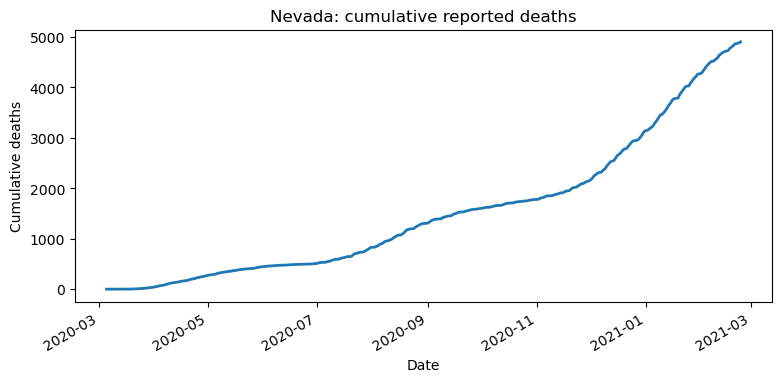

In [56]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(nv_df["date"], nv_df["death"], linewidth=2)
ax.set(title="Nevada: cumulative reported deaths", xlabel="Date", ylabel="Cumulative deaths")
fig.autofmt_xdate()
plt.show()

A daily series is often noisy. A 7-day rolling mean can make broad trends easier to see. `rolling(7).mean()` averages seven successive observations (after sorting by date).

AttributeError: 'Figure' object has no attribute 'autofmt_'

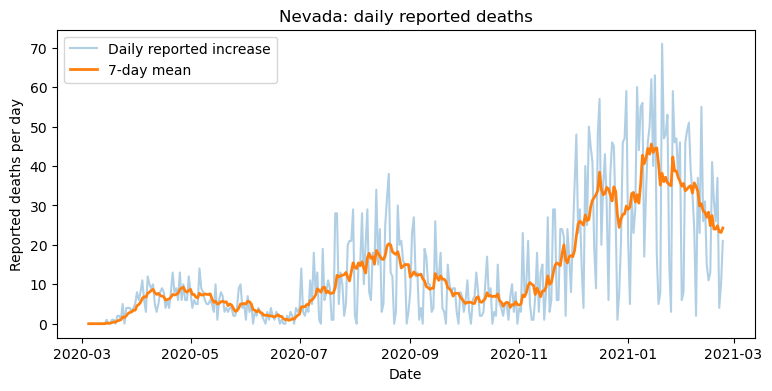

In [55]:
nv_df["deaths_7day_mean"] = nv_df["deathIncrease"].rolling(7, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(nv_df["date"], nv_df["deathIncrease"], alpha=0.35, label="Daily reported increase")
ax.plot(nv_df["date"], nv_df["deaths_7day_mean"], linewidth=2, label="7-day mean")
ax.set(title="Nevada: daily reported deaths", xlabel="Date", ylabel="Reported deaths per day")
ax.legend()
fig.autofmt_ 
xdate()
plt.show()

## VI. Introduction to `seaborn`

Seaborn works naturally with **long-format** DataFrames: each row is an observation and columns specify variables. Use `data=`, `x=`, `y=`, and sometimes `hue=`. For comparing states, choose a few rather than plotting all 50+ series together.

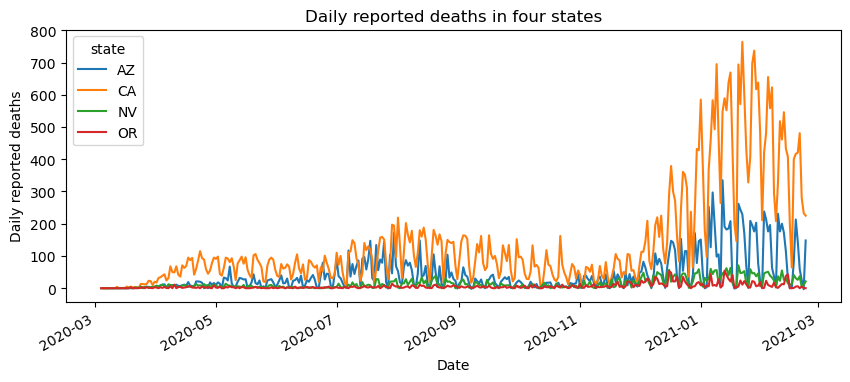

In [57]:
selected_df = working_df[working_df["state"].isin(["NV", "CA", "OR", "AZ"])].copy()
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=selected_df, x="date", y="deathIncrease", hue="state", ax=ax, estimator=None)
ax.set(title="Daily reported deaths in four states", xlabel="Date", ylabel="Daily reported deaths")
fig.autofmt_xdate()
plt.show()  


A boxplot compares distributions. Here each observation is a daily reported increase, not a cumulative total. A negative value can occur when historical records are revised.

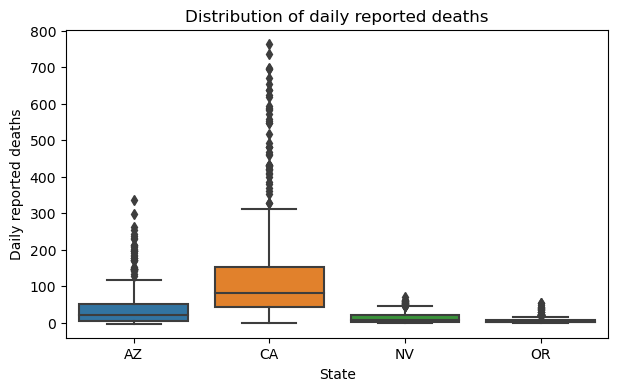

In [58]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=selected_df, x="state", y="deathIncrease", ax=ax)
ax.set(title="Distribution of daily reported deaths",
       xlabel="State",
       ylabel="Daily reported deaths")

plt.show()

A bar chart is useful for a small grouped summary. Here we use **means of daily increases**, rather than summing cumulative totals.

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=weekday_df.reset_index(), x="weekday", y="mean", ax=ax)
ax.set(title="Nevada: mean reported daily deaths by weekday", xlabel="Weekday", ylabel="Mean daily reported deaths")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### Saving figures

Save **before** `plt.show()` (or call `fig.savefig()` while the figure still exists). PDF and SVG are useful for scalable figures; PNG is useful for slides.

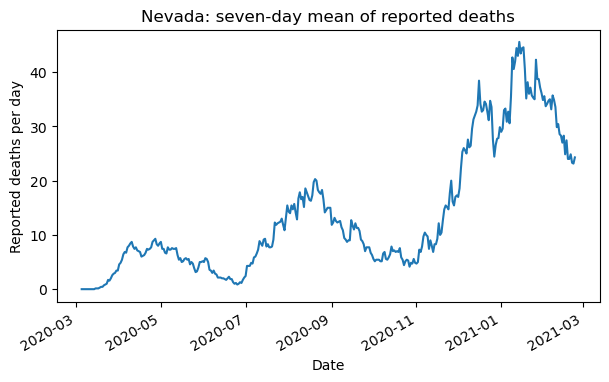

In [59]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(nv_df["date"], nv_df["deaths_7day_mean"])
ax.set(title="Nevada: seven-day mean of reported deaths", xlabel="Date", ylabel="Reported deaths per day")
fig.autofmt_xdate()
# fig.savefig("nv_daily_deaths.pdf", bbox_inches="tight")
plt.show()

### Seaborn: Violin plots

Violin plots are similar to boxplots but show more information about the shape of a distribution.

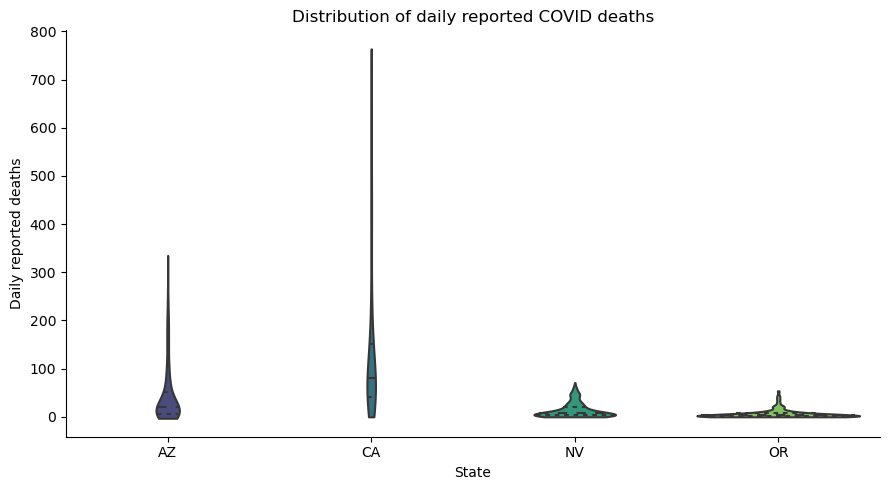

In [60]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.violinplot(
    data=selected_df,
    x="state",
    y="deathIncrease",
    palette="viridis",
    inner="quartile",
    cut=0,
    ax=ax
)

ax.set(
    title="Distribution of daily reported COVID deaths",
    xlabel="State",
    ylabel="Daily reported deaths"
)

sns.despine()
plt.tight_layout()
plt.show()

### Seaborn: Small multiples with FacetGrid

This is one of my favorite approaches for comparing patterns across groups.

Rather than putting every state on one figure, we create separate panels.

/Users/thomasparchman/anaconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


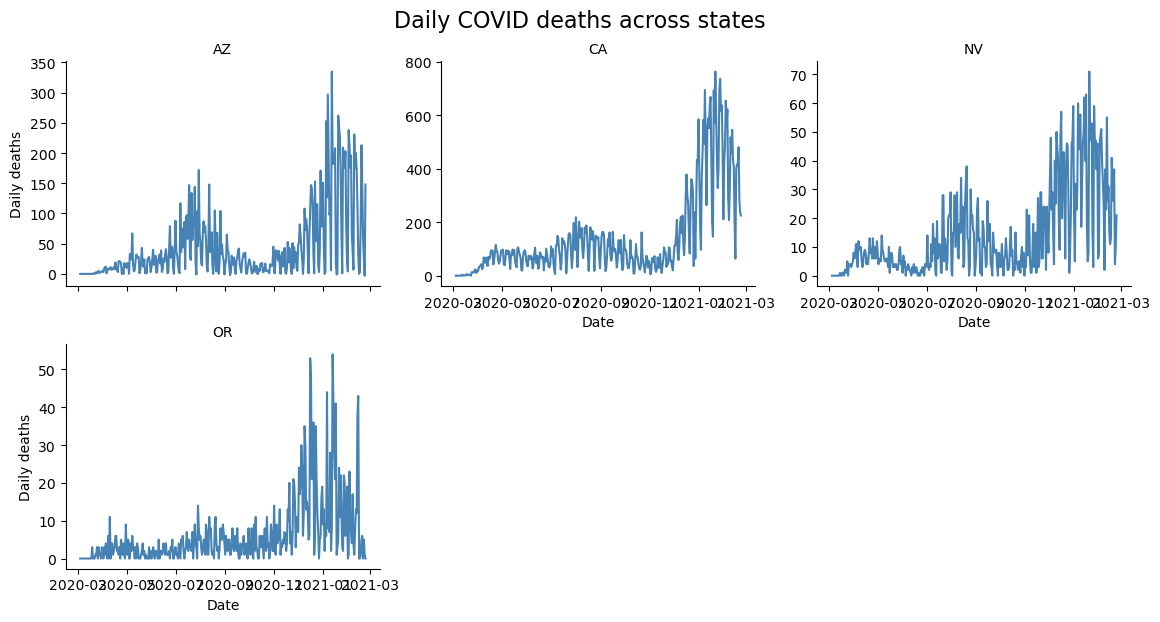

In [61]:
g = sns.relplot(
    data=selected_df,
    x="date",
    y="deathIncrease",
    col="state",
    col_wrap=3,
    kind="line",
    height=3,
    aspect=1.3,
    color="steelblue",
    facet_kws={"sharey": False}
)
g.set_axis_labels("Date", "Daily deaths")
g.set_titles("{col_name}")
g.fig.suptitle(
    "Daily COVID deaths across states",
    y=1.03,
    fontsize=16
)
plt.show()

### Seaborn: Heatmap of correlations

A very useful general-purpose visualization for multivariate biological datasets.

In [ ]:
# Select numerical variables
variables = [
    "death",
    "deathIncrease",
    "positive",
    "positiveIncrease",
    "total_tests"
]
# Calculate correlations
correlations = working_df[variables].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    correlations,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    fmt=".2f",
    ax=ax
)
ax.set_title("Correlations among COVID variables")
plt.tight_layout()
plt.show()

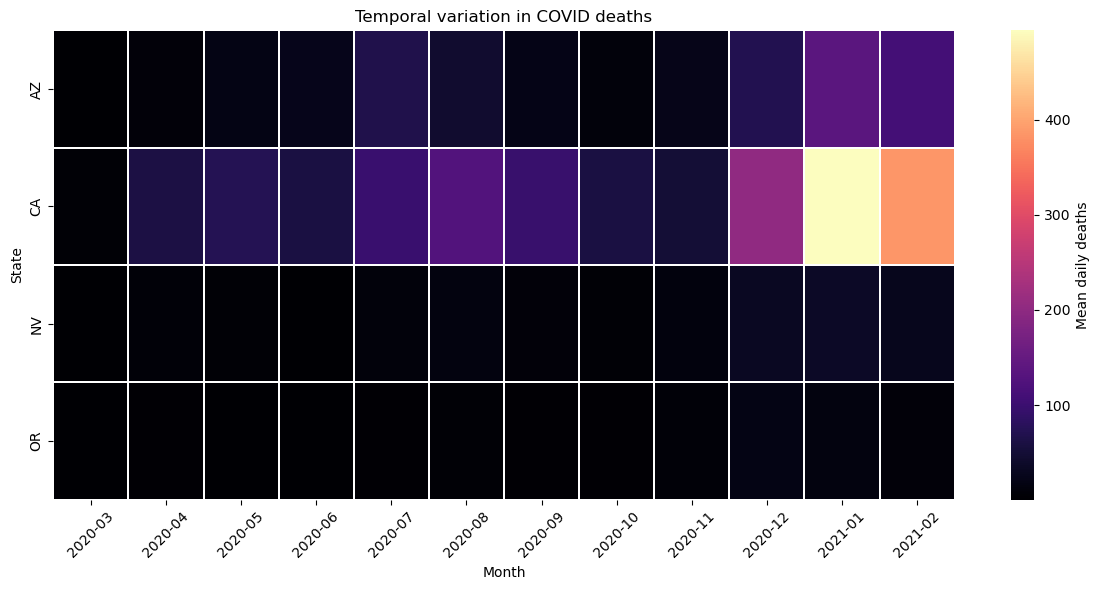

In [62]:
# Calculate average daily deaths by state and month
monthly_df = selected_df.copy()
monthly_df["month"] = monthly_df["date"].dt.to_period("M").astype(str)
monthly_summary = monthly_df.groupby(
    ["state", "month"]
)["deathIncrease"].mean().reset_index()
# Reshape to a matrix
heatmap_df = monthly_summary.pivot(
    index="state",
    columns="month",
    values="deathIncrease"
)
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(
    heatmap_df,
    cmap="magma",
    linewidths=0.3,
    cbar_kws={"label": "Mean daily deaths"},
    ax=ax
)
ax.set(
    title="Temporal variation in COVID deaths",
    xlabel="Month",
    ylabel="State"
)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Seaborn: Pairplot

A particularly powerful exploratory visualization.

/Users/thomasparchman/anaconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


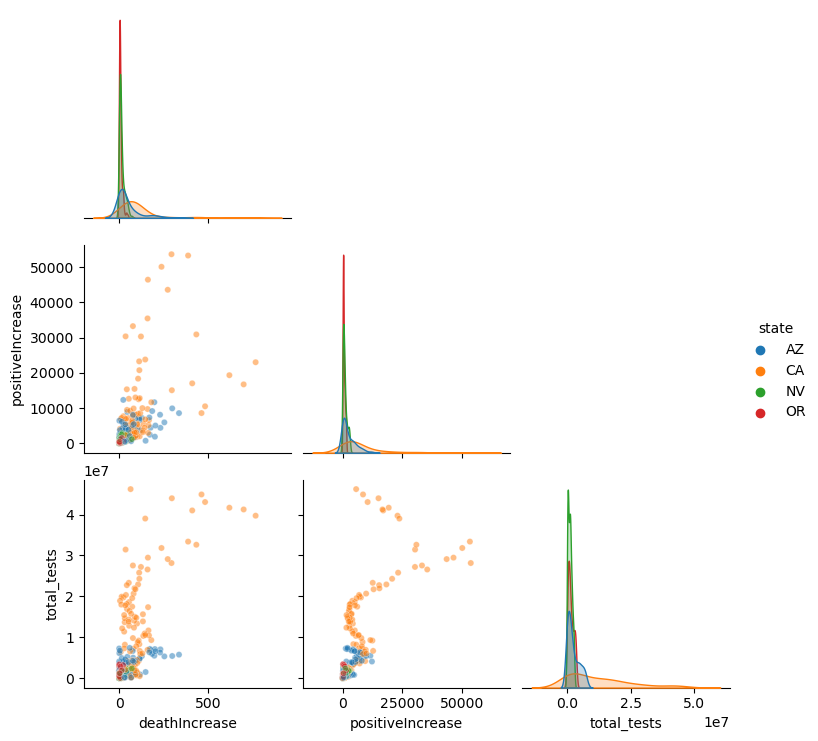

In [63]:
# Select a few variables and a manageable subset of observations
pair_df = selected_df[
    ["state", "deathIncrease", "positiveIncrease", "total_tests"]
].dropna()

pair_df = pair_df.sample(
    n=min(500, len(pair_df)),
    random_state=42
)
sns.pairplot(
    pair_df,
    vars=["deathIncrease", "positiveIncrease", "total_tests"],
    hue="state",
    corner=True,
    plot_kws={"alpha": 0.5, "s": 20}
)
plt.show()

### Interactive visualization with Plotly

Plotly introduces interactive graphics that students can explore in Jupyter notebooks or export as HTML.

First, import the library:

In [ ]:
import plotly.express as px

### plotly: interactive scatter plot

In [ ]:
fig = px.scatter(
    selected_df,
    x="positiveIncrease",
    y="deathIncrease",
    color="state",
    hover_data=["date"],
    title="Daily COVID cases and deaths",
    labels={
        "positiveIncrease": "Daily positive cases",
        "deathIncrease": "Daily deaths"
    },
    opacity=0.5
)

fig.update_layout(
    template="plotly_white",
    width=900,
    height=550
)

fig.show()

### plotly: interactive time series

In [ ]:
fig = px.line(
    selected_df.sort_values("date"),
    x="date",
    y="deathIncrease",
    color="state",
    title="Daily COVID deaths by state",
    labels={
        "date": "Date",
        "deathIncrease": "Daily deaths"
    }
)
fig.update_layout(
    template="plotly_white",
    hovermode="x unified",
    width=1000,
    height=550
)
fig.show()

### Plotly: Animated geographic map

This is one of the more visually engaging examples.

We can animate changes in COVID cases across the United States.

In [ ]:
map_df = working_df.copy()
# Select only dates with observations for at least 50 states
state_counts = map_df.groupby("date")["state"].transform("nunique")
map_df = map_df[state_counts >= 50].copy()
# Select Mondays to reduce animation size
map_df = map_df[map_df["date"].dt.dayofweek == 0].copy()
# Convert dates to strings for animation
map_df["date_string"] = map_df["date"].dt.strftime("%Y-%m-%d")
# Sort chronologically
map_df = map_df.sort_values("date")
# Create animated map
fig = px.choropleth(
    map_df,
    locations="state",
    locationmode="USA-states",
    color="positiveIncrease",
    animation_frame="date_string",
    scope="usa",
    color_continuous_scale="Viridis",
    range_color=(0, 20000),
    title="Daily reported COVID cases across the United States"
)
fig.update_layout(
    width=1000,
    height=650,
    geo=dict(bgcolor="rgba(0,0,0,0)")
)
fig.show()

 ### Plotly: Static choropleth map

For a simpler map, we can summarize the dataset by state.

In [ ]:
state_summary = working_df.groupby(
    "state"
)["positive"].max().reset_index()
fig = px.choropleth(
    state_summary,
    locations="state",
    locationmode="USA-states",
    color="positive",
    scope="usa",
    color_continuous_scale="Plasma",
    title="Maximum reported cumulative COVID cases by state",
    labels={"positive": "Cumulative cases"}
)
fig.update_layout(
    width=950,
    height=600
)
fig.show()

## VII. Try it yourself (optional practice)

1. Select data for two states of your choice and report their date ranges.
2. Find the five dates with the largest `positiveIncrease` for Nevada.
3. Use `groupby()` to calculate the mean daily reported cases (`positiveIncrease`) by state.
4. Plot the daily cases and a seven-day rolling mean for one state.
5. Make a labeled seaborn boxplot comparing daily cases across three states.

**Questions to consider:** What happens if you use cumulative `positive` instead of daily `positiveIncrease`? What does `NaN` mean in this dataset? How might reporting delays affect weekday patterns?

## Appendix: quick reference

| Task | Example |
|---|---|
| Load CSV | `pd.read_csv("file.csv")` |
| Inspect | `df.head()`, `df.shape`, `df.info()` |
| Select columns | `df[["state", "death"]]` |
| Select rows by label | `df.loc["NV"]` (after indexing by state) |
| Select by position | `df.iloc[:5, :3]` |
| Filter | `df[df["state"] == "NV"]` |
| Sort | `df.sort_values("date")` |
| Missing data | `df.isna().sum()` |
| Dates | `pd.to_datetime(...)`, `df["date"].dt.day_name()` |
| Group | `df.groupby("state")["deathIncrease"].mean()` |
| Save CSV | `df.to_csv("output.csv", index=False)` |
| Make figure | `fig, ax = plt.subplots()` |
| Plot | `ax.plot(x, y)`, `sns.boxplot(data=df, x="state", y="deathIncrease")` |
| Save figure | `fig.savefig("figure.pdf", bbox_inches="tight")` |

**Optional further exploration:** `sns.scatterplot()`, `sns.histplot()`, `sns.relplot()` and `plotly.express` for interactive graphics. The focus this week is on understanding DataFrame operations and producing a few clear, interpretable figures.